In [ ]:
import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

from typing import Tuple, List
from tqdm.auto import tqdm, trange
from IPython import display

import librosa
import librosa.display
from IPython.display import Audio

import copy

In [ ]:
random.seed(1337)
np.random.seed(1337)
torch.manual_seed(1337)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Часть 1. SPINN для 3D-уравнения Гельмгольца


Вспомогательные функций для точного решения, оценки ошибки и визуализации:

In [ ]:
def helmholtz3d_exact_u(a1, a2, a3, x, y, z):
    return (
        torch.sin(a1 * torch.pi * x)
        * torch.sin(a2 * torch.pi * y)
        * torch.sin(a3 * torch.pi * z)
    )


def relative_l2(u_pred, u_true):
    """Относительная L2-ошибка: ||u_pred - u_true|| / ||u_true||"""
    return torch.linalg.norm(u_pred - u_true) / torch.linalg.norm(u_true)

Вспомогательные функции для визуализации и оценки:

In [ ]:
def plot_helmholtz3d(x, y, z, u):
    x = x.detach().cpu().numpy().flatten()
    y = y.detach().cpu().numpy().flatten()
    z = z.detach().cpu().numpy().flatten()
    u = u.detach().cpu().numpy().flatten()

    u_norm = (u - u.min()) / (u.max() - u.min() + 1e-10)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        x, y, z,
        c=u_norm,
        s=1,
        cmap="seismic",
        vmin=0,
        vmax=1,
        alpha=0.75,
        edgecolors="none",
    )

    ax.set_title("U(x, y, z)", fontsize=18)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

    cbar = plt.colorbar(scatter, shrink=0.8, aspect=15)
    cbar.set_label("u(x,y,z)")

    plt.tight_layout()
    plt.show()


def plot_losses(
    loss_history,
    residual_history,
    boundary_history,
    error_history,
    log_iter,
    title_prefix="",
):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    ax1.semilogy(loss_history, label="Total Loss", linewidth=2)
    ax1.semilogy(residual_history, label="PDE Loss", alpha=0.7)
    ax1.semilogy(boundary_history, label="BC Loss", alpha=0.7)
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Loss (log scale)")
    ax1.set_title(f"{title_prefix}Training Losses")

    iterations = np.arange(0, len(error_history) * log_iter, log_iter)
    ax2.semilogy(iterations, error_history, "r-", linewidth=2, label="Relative L2 Error")
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Error (log scale)")
    ax2.set_title(f"{title_prefix}Relative L2 Error")

    plt.tight_layout()
    plt.show()


def compute_error_on_grid(model, x_grid, y_grid, z_grid, u_true):
    """
    Вычисление ошибки модели на фиксированной сетке.
    """

    was_training = model.training
    model.eval()

    with torch.no_grad():
        coords = torch.stack(
            [x_grid.flatten(), y_grid.flatten(), z_grid.flatten()],
            dim=1,
        )
        u_pred = model(coords)
        error = relative_l2(u_pred, u_true.flatten())

    if was_training:
        model.train()

    return error, u_pred.reshape(x_grid.shape)


def resample_collocation_points(model, NC, domain_size=1.0):
    """
    Ресэмплирование коллокационных точек на кубической решётке.
    """

    N_per_axis = int(round(NC ** (1 / 3)))

    x = torch.linspace(-domain_size, domain_size, N_per_axis, device=model.device)
    y = torch.linspace(-domain_size, domain_size, N_per_axis, device=model.device)
    z = torch.linspace(-domain_size, domain_size, N_per_axis, device=model.device)

    xx, yy, zz = torch.meshgrid(x, y, z, indexing="ij")

    xc = xx.flatten().requires_grad_(True)
    yc = yy.flatten().requires_grad_(True)
    zc = zz.flatten().requires_grad_(True)

    return xc, yc, zc

### Задание 1.1. Реализуйте SPINN-архитектуру

In [ ]:
# здесь ничего не меняем - изучаем, переиспользуем

class BaseModel(nn.Module):
    """
    Базовый класс для 3D-уравнения Гельмгольца на кубе [-1, 1]^3.

    Здесь уже реализованы:
    - точное решение и правая часть PDE;
    - граничные точки на 6 гранях куба;
    - вычисление PDE loss и BC loss.

    В этом задании предполагается, что студент реализует только
    архитектурную часть в наследнике BaseSPINN.
    """

    def __init__(
        self,
        x_min: float = -1.0,
        x_max: float = 1.0,
        y_min: float = -1.0,
        y_max: float = 1.0,
        z_min: float = -1.0,
        z_max: float = 1.0,
        k: float = 1.0,
        a1: int = 1,
        a2: int = 1,
        a3: int = 1,
        N_bc: int = 32,
        device: torch.device = None,
    ):
        super().__init__()
        self.x_min, self.x_max = x_min, x_max
        self.y_min, self.y_max = y_min, y_max
        self.z_min, self.z_max = z_min, z_max
        self.N_bc = N_bc
        self.k = k
        self.a1, self.a2, self.a3 = a1, a2, a3
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")

        self.mse = nn.MSELoss(reduction="mean")
        self._init_boundary_points()

    def _init_boundary_points(self):
        N = self.N_bc
        lin_x = torch.linspace(self.x_min, self.x_max, N)
        lin_y = torch.linspace(self.y_min, self.y_max, N)
        lin_z = torch.linspace(self.z_min, self.z_max, N)

        faces = []

        for x_val in [self.x_min, self.x_max]:
            yy, zz = torch.meshgrid(lin_y, lin_z, indexing="ij")
            xx = torch.full_like(yy, x_val)
            faces.append(torch.stack([xx.reshape(-1), yy.reshape(-1), zz.reshape(-1)], dim=1))

        for y_val in [self.y_min, self.y_max]:
            xx, zz = torch.meshgrid(lin_x, lin_z, indexing="ij")
            yy = torch.full_like(xx, y_val)
            faces.append(torch.stack([xx.reshape(-1), yy.reshape(-1), zz.reshape(-1)], dim=1))

        for z_val in [self.z_min, self.z_max]:
            xx, yy = torch.meshgrid(lin_x, lin_y, indexing="ij")
            zz = torch.full_like(xx, z_val)
            faces.append(torch.stack([xx.reshape(-1), yy.reshape(-1), zz.reshape(-1)], dim=1))

        for i, coords in enumerate(faces, 1):
            self.register_buffer(f"coords_bc{i}", coords.to(self.device))
            self.register_buffer(
                f"zeros_bc{i}",
                torch.zeros(coords.shape[0], 1, device=self.device)
            )

    def reference_solution(self, x, y, z):
        """Точное решение. Используется только для оценки ошибки."""
        return (
            torch.sin(self.a1 * np.pi * x)
            * torch.sin(self.a2 * np.pi * y)
            * torch.sin(self.a3 * np.pi * z)
        )

    def function_of_source(self, x, y, z):
        """Правая часть PDE, полученная подстановкой точного решения."""
        u = self.reference_solution(x, y, z)
        lap_coef = -(self.a1 * np.pi) ** 2 - (self.a2 * np.pi) ** 2 - (self.a3 * np.pi) ** 2
        return (lap_coef + self.k**2) * u

    def get_body_outputs(self, x, y, z):
        """
        Должен быть реализован в наследнике.

        Ожидаемые формы:
        - x: (Nx,), y: (Ny,), z: (Nz,)
        - f_x: (Nx, rank), f_y: (Ny, rank), f_z: (Nz, rank)
        """
        raise NotImplementedError

    def forward(self, x, y, z):
        """
        Значения решения на полной декартовой решётке.
        """
        raise NotImplementedError

    def forward_pointwise(self, coords):
        """
        Значения решения на произвольном наборе точек coords формы (B, 3).
        """
        raise NotImplementedError

    @staticmethod
    def _body_second_deriv(f, inp):
        """
        Вторая производная по одной координате для каждого канала ранга.
        Предполагается, что f.shape == (N, rank), inp.shape == (N,).
        """
        _, rank = f.shape
        d2 = torch.zeros_like(f)

        for r in range(rank):
            d1 = torch.autograd.grad(f[:, r].sum(), inp, create_graph=True)[0]
            d2[:, r] = torch.autograd.grad(d1.sum(), inp, create_graph=True)[0]

        return d2

    def calculate_pde_loss(self, x_col, y_col, z_col):
        """
        PDE loss на коллокационной решётке.
        """
        x = x_col.clone().detach().requires_grad_(True)
        y = y_col.clone().detach().requires_grad_(True)
        z = z_col.clone().detach().requires_grad_(True)

        f_x, f_y, f_z = self.get_body_outputs(x, y, z)

        f_x_d2 = self._body_second_deriv(f_x, x)
        f_y_d2 = self._body_second_deriv(f_y, y)
        f_z_d2 = self._body_second_deriv(f_z, z)

        u = self.forward(x, y, z)

        lap = (
            torch.einsum("ir,jr,kr->ijk", f_x_d2, f_y, f_z)
            + torch.einsum("ir,jr,kr->ijk", f_x, f_y_d2, f_z)
            + torch.einsum("ir,jr,kr->ijk", f_x, f_y, f_z_d2)
        )

        xx, yy, zz = torch.meshgrid(x, y, z, indexing="ij")
        q = self.function_of_source(xx, yy, zz)

        residual = lap + self.k**2 * u - q
        return self.mse(residual, torch.zeros_like(residual))

    def calculate_bc_loss(self):
        """
        MSE на шести гранях куба.
        """
        loss = torch.tensor(0.0, device=self.device)

        for i in range(1, 7):
            coords = getattr(self, f"coords_bc{i}")
            zeros = getattr(self, f"zeros_bc{i}")
            u_bc = self.forward_pointwise(coords).unsqueeze(-1)
            loss = loss + self.mse(u_bc, zeros)

        return loss

    def calculate_loss(self, x_col, y_col, z_col):
        loss_pde = self.calculate_pde_loss(x_col, y_col, z_col)
        loss_bc = self.calculate_bc_loss()
        return loss_pde, loss_bc

In [ ]:
class BaseSPINN(BaseModel):
    def __init__(
        self,
        x_min: float = -1.0,
        x_max: float = 1.0,
        y_min: float = -1.0,
        y_max: float = 1.0,
        z_min: float = -1.0,
        z_max: float = 1.0,
        k: float = 1.0,
        a1: int = 1,
        a2: int = 1,
        a3: int = 1,
        N_bc: int = 32,
        device: torch.device = None,
        rank: int = 32,
        hidden_dim: int = 64,
        num_layers: int = 3,
        act: nn.Module = nn.Tanh(),
    ):
      super().__init__(
          x_min=x_min,
          x_max=x_max,
          y_min=y_min,
          y_max=y_max,
          z_min=z_min,
          z_max=z_max,
          k=k,
          a1=a1,
          a2=a2,
          a3=a3,
          N_bc=N_bc,
          device=device,
      )

      self.rank = rank
      self.hidden_dim = hidden_dim
      self.num_layers = num_layers
      self.act = act

      self.body_x = self._make_body_net()
      self.body_y = self._make_body_net()
      self.body_z = self._make_body_net()

      self.apply(init_tanh_)

      self.to(self.device)

    def _make_body_net(self) -> nn.Module:
      if self.num_layers < 2:
        raise ValueError('num_layers might be >= 2')

      layers = []

      layers.append(nn.Linear(1, self.hidden_dim))
      layers.append(nn.Tanh())

      for _ in range(self.num_layers - 2):
        layers.append(nn.Linear(self.hidden_dim, self.hidden_dim))
        layers.append(nn.Tanh())

      layers.append(nn.Linear(self.hidden_dim, self.rank))

      return nn.Sequential(*layers)

    def get_body_outputs(self, x, y, z):
        x_in = x.unsqueeze(-1)
        y_in = y.unsqueeze(-1)
        z_in = z.unsqueeze(-1)

        f_x = self.body_x(x_in)
        f_y = self.body_y(y_in)
        f_z = self.body_z(z_in)

        return f_x, f_y, f_z

    def forward(self, x, y, z):
        f_x, f_y, f_z = self.get_body_outputs(x, y, z)

        u = torch.einsum('ir,jr,kr->ijk', f_x, f_y, f_z)

        return u

    def forward_pointwise(self, coords):
          if coords.ndim != 2 or coords.shape[1] != 3:
            raise ValueError('coords might be shape (B, 3)')

          x = coords[:, 0].unsqueeze(-1)
          y = coords[:, 1].unsqueeze(-1)
          z = coords[:, 2].unsqueeze(-1)

          f_x = self.body_x(x)
          f_y = self.body_y(y)
          f_z = self.body_z(z)

          u = (f_x * f_y * f_z).sum(dim=-1)

          return u


def init_tanh_(m: nn.Module):
    if isinstance(m, nn.Linear):
      gain = nn.init.calculate_gain('tanh')
      nn.init.xavier_uniform_(m.weight, gain=gain)

      if m.bias is not None:
        nn.init.zeros_(m.bias)

Проверка размерностей перед обучением:

In [ ]:
model = BaseSPINN(
    rank=16,
    hidden_dim=64,
    num_layers=3,
    device=device,
)

x = torch.linspace(-1, 1, 11, device=device)
y = torch.linspace(-1, 1, 13, device=device)
z = torch.linspace(-1, 1, 15, device=device)

f_x, f_y, f_z = model.get_body_outputs(x, y, z)
print('f_x shape: ', f_x.shape)
print('f_y shape: ', f_y.shape)
print('f_z shape: ', f_z.shape)

u_grid = model(x, y, z)
print('u_grid shape: ', u_grid.shape)

coords = torch.rand(20, 3, device=device) * 2 - 1
u_pointwise = model.forward_pointwise(coords)
print('u_pointwise shape: ', u_pointwise.shape)

f_x shape:  torch.Size([11, 16])
f_y shape:  torch.Size([13, 16])
f_z shape:  torch.Size([15, 16])
u_grid shape:  torch.Size([11, 13, 15])
u_pointwise shape:  torch.Size([20])


Код для обучения и оценки:

In [ ]:
def make_collocation_grid(N_per_axis, domain_size=1.0, device="cuda"):
    """
    Возвращает оси для декартовой коллокационной решётки
    Полная 3D-решётка содержит N_per_axis^3 точек
    """
    x = torch.linspace(-domain_size, domain_size, N_per_axis, device=device, requires_grad=True)
    y = torch.linspace(-domain_size, domain_size, N_per_axis, device=device, requires_grad=True)
    z = torch.linspace(-domain_size, domain_size, N_per_axis, device=device, requires_grad=True)
    return x, y, z

def compute_error_on_grid(model, x_grid, y_grid, z_grid, u_true):
    was_training = model.training
    model.eval()

    with torch.no_grad():
        u_pred = model(x_grid[:, 0, 0], y_grid[0, :, 0], z_grid[0, 0, :])
        error = relative_l2(u_pred, u_true)

    if was_training:
        model.train()

    return error, u_pred

def train_spinn(
    model,
    optimizer,
    x_test,
    y_test,
    z_test,
    u_test,
    epochs=10000,
    log_iter=100,
    resample_iter=100,
    N_per_axis=64,
    domain_size=1.0,
    device="cuda",
    scheduler=None,
    pde_weight=1.0,
    bc_weight=1.0,
):
    history = {
        "loss": [],
        "residual": [],
        "boundary": [],
        "error": [],
    }

    best_error = float("inf")
    best_u = None
    best_model_state = None #Добавила чтобы сохранить ЛУЧШУЮ, а не последнюю модель

    pbar = trange(1, epochs + 1)

    for epoch in pbar:
        if epoch == 1 or epoch % resample_iter == 0:
            xc, yc, zc = make_collocation_grid(N_per_axis, domain_size, device)

        optimizer.zero_grad()

        loss_pde, loss_bc = model.calculate_loss(xc, yc, zc)
        loss = pde_weight * loss_pde + bc_weight * loss_bc

        loss.backward()
        optimizer.step()

        if scheduler is not None:
            scheduler.step(loss)

        history["loss"].append(loss.item())
        history["residual"].append(loss_pde.item())
        history["boundary"].append(loss_bc.item())

        if epoch % log_iter == 0:
            error, u_pred = compute_error_on_grid(model, x_test, y_test, z_test, u_test)
            history["error"].append(error.item())

            if error < best_error:
                best_error = error
                best_u = u_pred.detach().clone()
                best_model_state = copy.deepcopy(model.state_dict()) #для сохранения лучшей модели

            display.clear_output(wait=True)
            plot_losses(
                history["loss"],
                history["residual"],
                history["boundary"],
                history["error"],
                log_iter,
            )

            if error <= best_error:
                print(f"New best: rel L2 = {best_error:.2e}")
                plot_helmholtz3d(x_test, y_test, z_test, u_pred)

            pbar.set_description(
                f"L={loss.item():.2e} | PDE={loss_pde.item():.2e} | "
                f"BC={loss_bc.item():.2e} | err={error.item():.2e} | best={best_error:.2e}"
            )

    print(f"\nDone. Best relative L2 error: {best_error:.2e}")

    display.clear_output(wait=True)
    plot_losses(
        history["loss"],
        history["residual"],
        history["boundary"],
        history["error"],
        log_iter,
        title_prefix="Final ",
    )

    if best_u is not None:
        plot_helmholtz3d(x_test, y_test, z_test, best_u)

    if best_model_state is not None:
        torch.save(best_model_state, 'best_spinn_model.pth')

    return history, best_error, best_u

### Задание 1.2. Обучите модель

In [ ]:
# YOUR CODE: выберите конфигурацию модели, оптимизатор и параметры обучения
# ヾ(๑╹◡╹)ﾉ

EPOCHS = 20000
LOG_ITER = 500
RESAMPLE_ITER = EPOCHS + 1
N_PER_AXIS = 32

N_TEST = 48
x_lin = torch.linspace(-1.0, 1.0, N_TEST, device=device)
y_lin = torch.linspace(-1.0, 1.0, N_TEST, device=device)
z_lin = torch.linspace(-1.0, 1.0, N_TEST, device=device)
xx_test, yy_test, zz_test = torch.meshgrid(x_lin, y_lin, z_lin, indexing='ij')

u_test = model.reference_solution(xx_test, yy_test, zz_test)

model = BaseSPINN(
    rank=1,
    hidden_dim=32,
    num_layers=3,
    N_bc=32,
    k=1.0,
    a1=1,
    a2=1,
    a3=1,
    device=device,
).to(device)

model.apply(init_tanh_)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=1000,
    min_lr=1e-6,
)

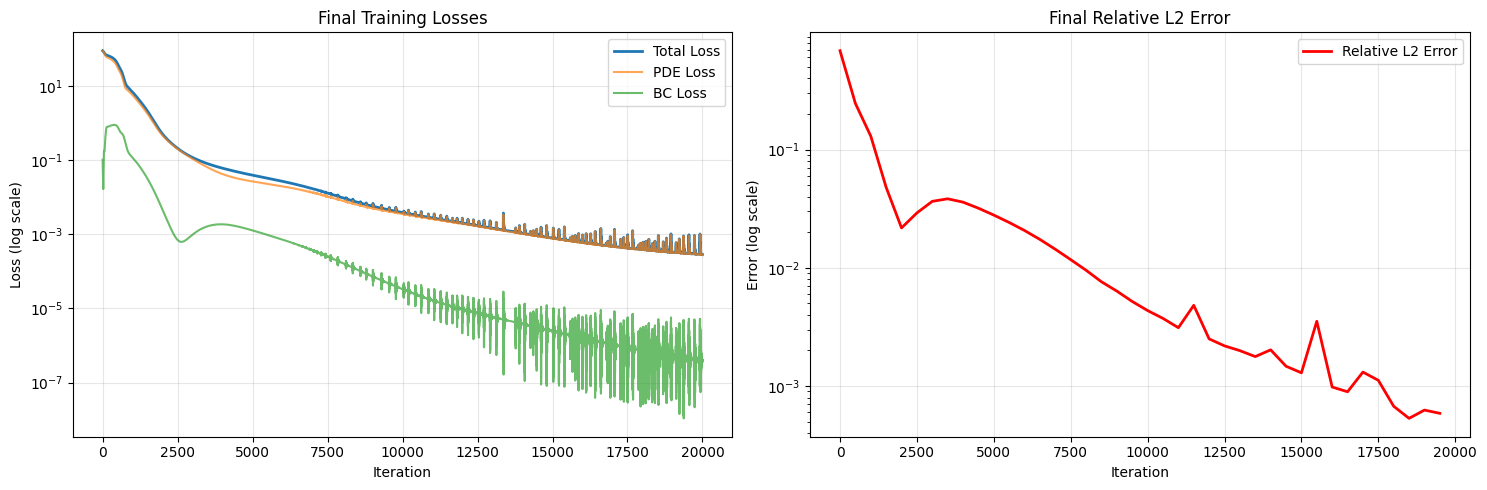

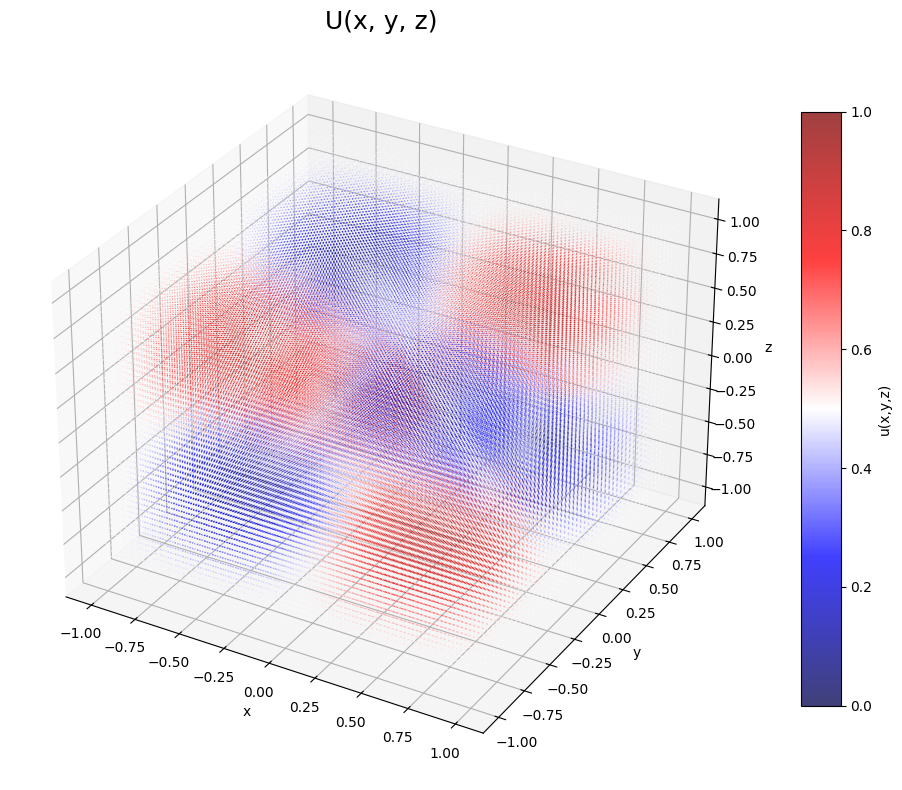

In [ ]:
history, best_error, best_u = train_spinn(
    model=model,
    optimizer=optimizer,
    x_test=xx_test,
    y_test=yy_test,
    z_test=zz_test,
    u_test=u_test,
    epochs=EPOCHS,
    log_iter=LOG_ITER,
    resample_iter=RESAMPLE_ITER,
    N_per_axis=N_PER_AXIS,
    domain_size=1.0,
    device=device,
    scheduler=scheduler,
    pde_weight=1.0,
    bc_weight=10.0,
)

In [ ]:
model.eval()
with torch.no_grad():
    u_pred_final = model(xx_test[:, 0, 0], yy_test[0, :, 0], zz_test[0, 0, :])

mse = ((u_test.cpu().numpy() - u_pred_final.cpu().numpy()) ** 2).mean()
rel_l2 = relative_l2(u_pred_final, u_test).item()

print(f"MSE: {mse:.2e}")
print(f"Relative L2: {rel_l2:.2e}")

MSE: 4.06e-08
Relative L2: 5.88e-04


In [ ]:
score_1_2 = 0.0
if mse <= 5e-3:
    score_1_2 = 0.5 * 1.5
if mse <= 5e-4:
    score_1_2 = 0.6 * 1.5
if mse <= 1e-5:
    score_1_2 = 0.7 * 1.5
if mse <= 1e-7:
    score_1_2 = 0.9 * 1.5
if mse <= 5e-8:
    score_1_2 = 1.0 * 1.5

print(f"Баллы за пункт 1.2: {score_1_2:.2f} / 1.5")

Баллы за пункт 1.2: 1.50 / 1.5


### Задание 1.3. Краткий анализ

1. Параметры, с которых начинала:

    EPOCHS = 10000

    RESAMPLE_ITER = 50

    N_PER_AXIS = 24

    rank=32

    hidden_dim=64

    num_layers=3

    N_bc=32

    lr=1e-3

  Итоговая конфигурация:

  EPOCHS = **20000**

  RESAMPLE_ITER = **EPOCHS + 1**

  N_PER_AXIS = **32**

  rank=**1**

  hidden_dim=64

  num_layers=3

  N_bc=32

  lr=**1e-4**


2. Влияние rank на качество и время обучения.

Я начала с rank=32 далее увеличивала его, при этом **время обучения увеличивалось**, а **качество модели менялось незначительно** (иногда даже снижалось). При этом при rank=1 качество модели не ухудшилось, но уменьшилось время, подкрутив другие параметры (lr=1e-3 -> lr=1e-4, EPOCHS=10000 -> EPOCHS=20000, RESAMPLE_ITER=50->RESAMPLE_ITER=EPOCHS + 1) я получила значительно лучший результат.

3. Влияние архитектуры body-сетей, плотности коллокационной решётки или баланса между `PDE loss` и `BC loss`.

Я не меняла архитектуру body-сетей в хрде экспериментов, поэтому, к сожалению, не могу сказать о влиянии.

При увеличении плотности коллокационной решетки, модель улучшила результаты. До увеличения PDE loss падал, но error оставался примерно на уровне ~1e-2, 1e-1.

Я думаю, что баланс между PDE loss и BC loss важен (так как в некоторых экспериментах было видно, что PDE сходился значительно медленнее), но кажется, мне повезло и я изначально задала подходящие значения, в ходе экспериментов я их немного меняла, однако наилучший результат был достигнут при первоначальных значениях.



4. Были ли признаки того, что модель реализована некорректно или обучается неустойчиво, и как вы это диагностировали.

Признаков багов у меня не было: PDE и BC loss снижались, error тоже убывал. При этом увеличение rank и hidden_dim не помогало, соответственно с архитектурой все ок.

Главной проблемой был выход error на плато. Оптимальная модель была получена путем, описанным в пункте 2.

## Часть 2. Классификация звуков UrbanSound8K с помощью CNN

In [ ]:
import os
import hashlib
from pathlib import Path

from tqdm.notebook import tqdm

import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

from typing import Tuple, List
from tqdm.auto import tqdm, trange
from IPython import display

import librosa
import librosa.display
from IPython.display import Audio

import copy

import seaborn as sns

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/urbansound8k_data'

Mounted at /content/drive


In [ ]:
metadata = pd.read_csv(f'{DATASET_PATH}/metadata/UrbanSound8K.csv')
metadata.head(5)

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


In [ ]:
metadata['audio_path'] = metadata.apply(
    lambda row: f'{DATASET_PATH}/audio/fold{row['fold']}/{row['slice_file_name']}',
    axis=1
)

In [ ]:
print(f"Всего примеров: {len(metadata)}")
print("\nРаспределение по классам:")
print(metadata["class"].value_counts().sort_index())
print("\nРаспределение по fold'ам:")
print(metadata["fold"].value_counts().sort_index())

Всего примеров: 8732

Распределение по классам:
class
air_conditioner     1000
car_horn             429
children_playing    1000
dog_bark            1000
drilling            1000
engine_idling       1000
gun_shot             374
jackhammer          1000
siren                929
street_music        1000
Name: count, dtype: int64

Распределение по fold'ам:
fold
1     873
2     888
3     925
4     990
5     936
6     823
7     838
8     806
9     816
10    837
Name: count, dtype: int64


### Задание 2.1. Подготовьте датасет к обучению модели

In [ ]:

# Единый LabelEncoder

ALL_CLASSES = sorted(metadata["class"].unique())
global_label_encoder = LabelEncoder()
global_label_encoder.fit(ALL_CLASSES)

print(f"Классы ({len(global_label_encoder.classes_)}):")
print(list(global_label_encoder.classes_))

Классы (10):
[np.str_('air_conditioner'), np.str_('car_horn'), np.str_('children_playing'), np.str_('dog_bark'), np.str_('drilling'), np.str_('engine_idling'), np.str_('gun_shot'), np.str_('jackhammer'), np.str_('siren'), np.str_('street_music')]


In [ ]:
from pandas._libs import lib
class UrbanSoundDataset(Dataset):
    def __init__(
        self,
        metadata,
        dataset_path,
        label_encoder,
        target_length=4,
        sr=22050,
        n_mels=128,
        augment=False,
        cache_dir=None,
    ):
        self.metadata = metadata.reset_index(drop=True).copy()
        self.dataset_path = dataset_path
        self.label_encoder = label_encoder
        self.target_length = target_length
        self.sr = sr
        self.n_mels = n_mels
        self.augment = augment
        self.target_num_samples = int(target_length * sr)

        self.file_paths = self.metadata['audio_path'].tolist()

        if 'class' in self.metadata.columns:
          self.labels = self.label_encoder.transform(self.metadata['class'].values)
        elif 'classID' in self.metadata.columns:
          self.labels = self.metadata['classID'].astype(int).values

        self.cache_dir = Path(cache_dir) if cache_dir is not None else None
        if self.cache_dir is not None:
          self.cache_dir.mkdir(parents=True, exist_ok=True)

        self.memory_cache = {} if self.cache_dir is None else None
        self.cache_index = []

        self._prepare_cache()

    def __len__(self):
        return len(self.metadata)

    def _make_cache_path(self, file_path):
      key = f'{file_path}|sr={self.sr}|target={self.target_length}|n_mels={self.n_mels}'
      key_hash = hashlib.md5(key.encode('utf-8')).hexdigest()
      return self.cache_dir / f'{key_hash}.npy'

    def _prepare_cache(self):
      for idx, file_path in enumerate(self.file_paths):
        if self.cache_dir is None:
          y = self.load_audio(file_path)
          mel = self.extract_mel_spectrogram(y)
          self.memory_cache[idx] = mel
          self.cache_index.append(idx)
        else:
          cache_path = self._make_cache_path(file_path)
          if not cache_path.exists():
            y = self.load_audio(file_path)
            mel = self.extract_mel_spectrogram(y)
            np.sasve(cache_path, mel.astype(np.float32))
          self.cache_index.append(cache_path)

    def load_audio(self, file_path):
        y, _ = librosa.load(file_path, sr=self.sr, mono=True)

        if len(y) < self.target_num_samples:
          pad_size = self.target_num_samples - len(y)
          y = np.pad(y, (0, pad_size), mode='constant')
        else:
          y = y[: self.target_num_samples]

        return y.astype(np.float32)

    def extract_mel_spectrogram(self, y):
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=self.sr,
            n_mels=self.n_mels,
            power=2.0,
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)

        mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-8)

        return mel_db.astype(np.float32)

    def augment_audio(self, y):
        y = y.copy()

        if np.random.rand() < 0.5:
          gain = np.random.uniform(0.8, 1.2)
          y = y * gain

        if np.random.rand() < 0.5:
          noise = np.random.normal(0, 0.005, size=len(y)).astype(np.float32)
          y = y + noise

        if np.random.rand() < 0.5:
          max_shift = int(0.1 * self.sr)
          shift = np.random.randint(-max_shift, max_shift + 1)
          y = np.roll(y, shift)

        y = np.clip(y, -1.0, 1.0)
        return y.astype(np.float32)

    def _spec_augment(self, mel_tensor, max_freq_mask=12, max_time_mask=20):
        mel = mel_tensor.clone()
        _, n_mels, time_steps = mel.shape

        if np.random.rand() < 0.5:
          freq_mask = np.random.randint(0, min(max_freq_mask, n_mels) + 1)
          if freq_mask > 0:
            f0 = np.random.randint(0, n_mels - freq_mask + 1)
            mel[:, f0:f0 + freq_mask, :] = 0

        if np.random.rand() < 0.5:
          time_mask = np.random.randint(0, min(max_time_mask, time_steps) + 1)
          if time_mask > 0:
            t0 = np.random.randint(0, time_steps - time_mask + 1)
            mel[:, :, t0:t0 + time_mask] = 0

        return mel

    def __getitem__(self, idx):
        if self.cache_dir is None:
          mel = self.memory_cache[idx]
        else:
          mel = np.load(self.cache_index[idx])

        mel = torch.tensor(mel, dtype=torch.float32).unsqueeze(0)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        if self.augment:
          mel = self._spec_augment(mel)

        return mel, label

In [ ]:
def get_fold_split(metadata, test_fold, val_fold=None):
    """
    Разбиение по official folds.

    """
    test_df = metadata[metadata["fold"] == test_fold]

    if val_fold is not None:
        assert val_fold != test_fold
        val_df = metadata[metadata["fold"] == val_fold]
        train_folds = [f for f in range(1, 11) if f not in {test_fold, val_fold}]
    else:
        val_df = None
        train_folds = [f for f in range(1, 11) if f != test_fold]

    train_df = metadata[metadata["fold"].isin(train_folds)]

    print(
        f"test={test_fold}"
        + (f", val={val_fold}" if val_fold is not None else "")
        + f" | Train: {len(train_df)}, Val: {len(val_df) if val_df is not None else 0}, Test: {len(test_df)}"
    )
    return train_df, val_df, test_df

In [ ]:
train_df, val_df, test_df = get_fold_split(metadata, test_fold=10, val_fold=9)

BATCH_SIZE = 64

train_dataset = UrbanSoundDataset(
    train_df,
    DATASET_PATH,
    global_label_encoder,
    augment=True,
)

val_dataset = UrbanSoundDataset(
    val_df,
    DATASET_PATH,
    global_label_encoder,
    augment=False,
)

test_dataset = UrbanSoundDataset(
    test_df,
    DATASET_PATH,
    global_label_encoder,
    augment=False,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

sample_batch, sample_labels = next(iter(train_loader))
print(f"Batch shape: {sample_batch.shape}")
print(f"Labels shape: {sample_labels.shape}")
print(f"First labels: {sample_labels[:5]}")

test=10, val=9 | Train: 7079, Val: 816, Test: 837


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Batch shape: torch.Size([64, 1, 128, 173])
Labels shape: torch.Size([64])
First labels: tensor([4, 0, 0, 8, 4])


### Задание 2.2. Реализуйте вашу архитектуру


In [ ]:
class UrbanSoundCNN(nn.Module):
  def __init__(self, num_classes=10, dropout=0.5, channels=[1, 32, 64, 128, 256], fc_dim=128):
      super().__init__()

      self.features = nn.Sequential(
          nn.Conv2d(channels[0], channels[1], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[1]),
          nn.ReLU(inplace=True),
          nn.Conv2d(channels[1], channels[1], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[1]),
          nn.ReLU(inplace=True),
          nn.MaxPool2d(2),
          nn.Dropout2d(0.1),

          nn.Conv2d(channels[1], channels[2], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[2]),
          nn.ReLU(inplace=True),
          nn.Conv2d(channels[2], channels[2], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[2]),
          nn.ReLU(inplace=True),
          nn.MaxPool2d(2),
          nn.Dropout2d(0.15),

          nn.Conv2d(channels[2], channels[3], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[3]),
          nn.ReLU(inplace=True),
          nn.Conv2d(channels[3], channels[3], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[3]),
          nn.ReLU(inplace=True),
          nn.MaxPool2d(2),
          nn.Dropout2d(0.2),

          nn.Conv2d(channels[3], channels[4], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[4]),
          nn.ReLU(inplace=True),
          nn.Conv2d(channels[4], channels[4], kernel_size=3, padding=1),
          nn.BatchNorm2d(channels[4]),
          nn.ReLU(inplace=True),
          nn.MaxPool2d(2),
          nn.Dropout2d(0.25),
      )

      self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

      self.classifier = nn.Sequential(
          nn.Flatten(),
          nn.Linear(channels[-1], fc_dim),
          nn.ReLU(inplace=True),
          nn.Dropout(dropout),
          nn.Linear(fc_dim, num_classes),
      )

  def forward(self, x):
      x = self.features(x)
      x = self.global_pool(x)
      x = self.classifier(x)
      return x

### Задание 2.3. Реализуйте обучение и валидацию модели

In [ ]:
# TODO (⌐■_■):
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        running_loss += loss.item() * x.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

model = UrbanSoundCNN(num_classes=10).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("\nModel:")
print(model)

Total parameters: 1,207,786
Trainable parameters: 1,207,786

Model:
UrbanSoundCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=T

In [ ]:
import copy

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3,
)

NUM_EPOCHS = 50
PATIENCE = 15
BEST_MODEL_PATH = '/content/drive/MyDrive/urbansound8k_best_model.pt'

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
}

best_val_acc = 0.0
best_epoch = 0
best_model_weights = copy.deepcopy(model.state_dict())
patience_counter = 0

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    scheduler.step(val_acc)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(
        f'Epoch [{epoch + 1} / {NUM_EPOCHS}] | '
        f'train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | '
        f'val_loss={val_loss:.4f}, val_acc={val_acc:.4f}'
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_model_weights = copy.deepcopy(model.state_dict())
        torch.save(best_model_weights, BEST_MODEL_PATH)
        patience_counter = 0
        print(f' -> Best model saved. val_acc={best_val_acc:.4f}')
    else:
        patience_counter += 1
        print(f' -> No improvement. Patience: {patience_counter} / {PATIENCE}')

    if patience_counter >= PATIENCE:
        print('Early stopping triggered.')
        break

model.load_state_dict(best_model_weights)

print(f'\nBest val_acc: {best_val_acc:.4f} at epoch {best_epoch}')

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1 / 50] | train_loss=1.8044, train_acc=0.3372 | val_loss=1.5812, val_acc=0.4473
 -> Best model saved. val_acc=0.4473
Epoch [2 / 50] | train_loss=1.3281, train_acc=0.5189 | val_loss=1.3236, val_acc=0.5968
 -> Best model saved. val_acc=0.5968
Epoch [3 / 50] | train_loss=1.1250, train_acc=0.5922 | val_loss=1.0524, val_acc=0.6373
 -> Best model saved. val_acc=0.6373
Epoch [4 / 50] | train_loss=1.0384, train_acc=0.6258 | val_loss=1.0265, val_acc=0.6029
 -> No improvement. Patience: 1 / 15
Epoch [5 / 50] | train_loss=0.9259, train_acc=0.6726 | val_loss=1.0121, val_acc=0.6826
 -> Best model saved. val_acc=0.6826
Epoch [6 / 50] | train_loss=0.8672, train_acc=0.6977 | val_loss=0.9396, val_acc=0.6667
 -> No improvement. Patience: 1 / 15
Epoch [7 / 50] | train_loss=0.8011, train_acc=0.7312 | val_loss=0.9586, val_acc=0.7230
 -> Best model saved. val_acc=0.7230
Epoch [8 / 50] | train_loss=0.7575, train_acc=0.7471 | val_loss=0.9190, val_acc=0.6998
 -> No improvement. Patience: 1 / 15
Epoch [9

In [ ]:
model.load_state_dict(torch.load("/content/drive/MyDrive/urbansound8k_best_model.pt", map_location=device))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"Test accuracy on dev-split: {test_acc * 100:.2f}%")

Testing:   0%|          | 0/14 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Test accuracy on dev-split: 81.12%


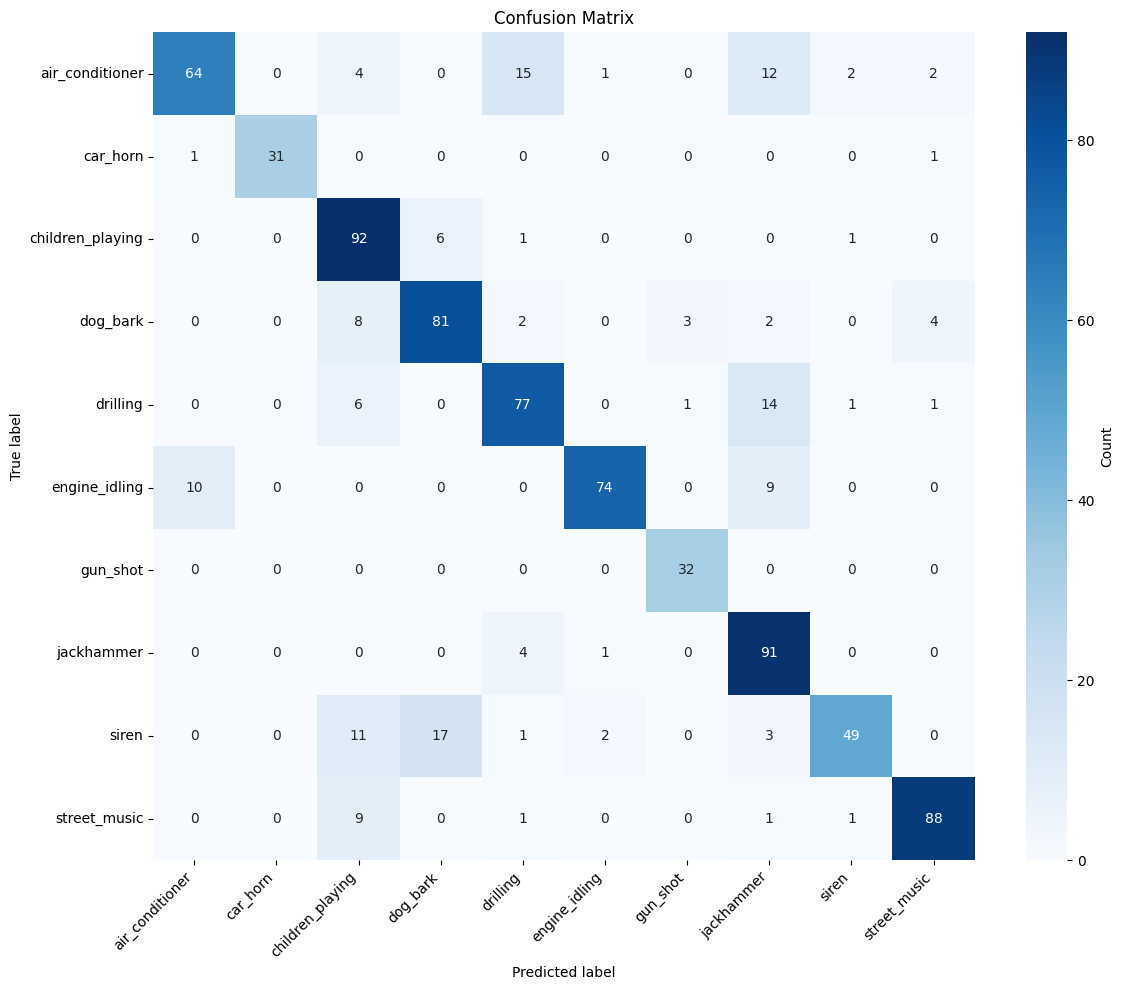

                  precision    recall  f1-score   support

 air_conditioner     0.8533    0.6400    0.7314       100
        car_horn     1.0000    0.9394    0.9688        33
children_playing     0.7077    0.9200    0.8000       100
        dog_bark     0.7788    0.8100    0.7941       100
        drilling     0.7624    0.7700    0.7662       100
   engine_idling     0.9487    0.7957    0.8655        93
        gun_shot     0.8889    1.0000    0.9412        32
      jackhammer     0.6894    0.9479    0.7982        96
           siren     0.9074    0.5904    0.7153        83
    street_music     0.9167    0.8800    0.8980       100

        accuracy                         0.8112       837
       macro avg     0.8453    0.8293    0.8279       837
    weighted avg     0.8280    0.8112    0.8095       837



In [ ]:
cm = confusion_matrix(all_labels, all_preds)
class_names = global_label_encoder.classes_

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Count"},
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

### Задание 2.4. Финальная 10-fold оценка

In [ ]:
def evaluate_10fold(
    model_class,
    model_kwargs,
    train_fn,
    metadata,
    dataset_path,
    label_encoder,
    device="cuda",
    verbose=True,
):
    """
    10-fold CV по folds UrbanSound8K
    """
    accuracies = []

    for test_fold in range(1, 11):
        val_fold = 1 if test_fold == 10 else test_fold + 1
        train_folds = [f for f in range(1, 11) if f not in {test_fold, val_fold}]

        if verbose:
            print(f"\n{'=' * 50}")
            print(f"Fold {test_fold}/10 (val={val_fold}, train={train_folds})")

        train_df = metadata[metadata["fold"].isin(train_folds)]
        val_df = metadata[metadata["fold"] == val_fold]
        test_df = metadata[metadata["fold"] == test_fold]

        train_ds = UrbanSoundDataset(train_df, dataset_path, label_encoder, augment=True)
        val_ds = UrbanSoundDataset(val_df, dataset_path, label_encoder, augment=False)
        test_ds = UrbanSoundDataset(test_df, dataset_path, label_encoder, augment=False)

        loader_kwargs = dict(num_workers=4, pin_memory=True)
        train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, **loader_kwargs)
        val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, **loader_kwargs)
        test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, **loader_kwargs)

        model = model_class(**model_kwargs).to(device)
        model = train_fn(model, train_loader, val_loader, device)

        model.eval()
        all_preds, all_labels = [], []

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device)
                preds = model(inputs).argmax(1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.numpy())

        acc = np.mean(np.array(all_preds) == np.array(all_labels))
        accuracies.append(acc)

        if verbose:
            print(f"Fold {test_fold} accuracy: {acc * 100:.2f}%")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    mean_acc = np.mean(accuracies)
    std_acc = np.std(accuracies)

    if verbose:
        print(f"\n{'=' * 50}")
        print(f"10-fold CV: {mean_acc * 100:.2f}% ± {std_acc * 100:.2f}%")

    return accuracies

In [ ]:
def my_train_fn(model, train_loader, val_loader, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.5,
        patience=3,
    )

    NUM_EPOCHS = 50
    PATIENCE = 15

    best_val_acc = 0.0
    best_model_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
    }

    for epoch in range(NUM_EPOCHS):
      train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
      val_loss, val_acc = validate(model, val_loader, criterion, device)

      scheduler.step(val_acc)

      history['train_loss'].append(train_loss)
      history['train_acc'].append(train_acc)
      history['val_loss'].append(val_loss)
      history['val_acc'].append(val_acc)

      print(
          f'Epoch [{epoch + 1} / {NUM_EPOCHS}] | '
          f'train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | '
          f'val_loss={val_loss:.4f}, val_acc={val_acc:.4f}'
      )

      if val_acc > best_val_acc:
          best_val_acc = val_acc
          best_epoch = epoch + 1
          best_model_weights = copy.deepcopy(model.state_dict())
          torch.save(best_model_weights, BEST_MODEL_PATH)
          patience_counter = 0
          print(f' -> Best model saved. val_acc={best_val_acc:.4f}')
      else:
          patience_counter += 1
          print(f' -> No improvement. Patience: {patience_counter} / {PATIENCE}')

      if patience_counter >= PATIENCE:
          print('Early stopping triggered.')
          break

    model.load_state_dict(best_model_weights)
    return model


In [ ]:
accuracies = evaluate_10fold(
    model_class=UrbanSoundCNN,
    model_kwargs={"num_classes": 10},
    train_fn=my_train_fn,
    metadata=metadata,
    dataset_path=DATASET_PATH,
    label_encoder=global_label_encoder,
    device=device,
)


Fold 1/10 (val=2, train=[3, 4, 5, 6, 7, 8, 9, 10])


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1 / 50] | train_loss=1.8606, train_acc=0.3089 | val_loss=1.4502, val_acc=0.4200
 -> Best model saved. val_acc=0.4200
Epoch [2 / 50] | train_loss=1.3948, train_acc=0.4919 | val_loss=1.1790, val_acc=0.5450
 -> Best model saved. val_acc=0.5450
Epoch [3 / 50] | train_loss=1.1936, train_acc=0.5691 | val_loss=1.0089, val_acc=0.6047
 -> Best model saved. val_acc=0.6047
Epoch [4 / 50] | train_loss=1.0498, train_acc=0.6262 | val_loss=1.1344, val_acc=0.5563
 -> No improvement. Patience: 1 / 15
Epoch [5 / 50] | train_loss=0.9564, train_acc=0.6646 | val_loss=0.9898, val_acc=0.6318
 -> Best model saved. val_acc=0.6318
Epoch [6 / 50] | train_loss=0.8592, train_acc=0.7075 | val_loss=0.8302, val_acc=0.7117
 -> Best model saved. val_acc=0.7117
Epoch [7 / 50] | train_loss=0.7986, train_acc=0.7317 | val_loss=0.7903, val_acc=0.7252
 -> Best model saved. val_acc=0.7252
Epoch [8 / 50] | train_loss=0.7398, train_acc=0.7510 | val_loss=0.9462, val_acc=0.6993
 -> No improvement. Patience: 1 / 15
Epoch [9

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1 / 50] | train_loss=1.8239, train_acc=0.3272 | val_loss=1.4913, val_acc=0.4119
 -> Best model saved. val_acc=0.4119
Epoch [2 / 50] | train_loss=1.4268, train_acc=0.4803 | val_loss=1.3186, val_acc=0.5049
 -> Best model saved. val_acc=0.5049
Epoch [3 / 50] | train_loss=1.2291, train_acc=0.5504 | val_loss=1.2331, val_acc=0.5524
 -> Best model saved. val_acc=0.5524
Epoch [4 / 50] | train_loss=1.1173, train_acc=0.5939 | val_loss=1.1413, val_acc=0.5622
 -> Best model saved. val_acc=0.5622
Epoch [5 / 50] | train_loss=0.9838, train_acc=0.6552 | val_loss=1.2285, val_acc=0.5589
 -> No improvement. Patience: 1 / 15
Epoch [6 / 50] | train_loss=0.9201, train_acc=0.6867 | val_loss=1.1009, val_acc=0.5989
 -> Best model saved. val_acc=0.5989
Epoch [7 / 50] | train_loss=0.8533, train_acc=0.7169 | val_loss=1.1958, val_acc=0.6238
 -> Best model saved. val_acc=0.6238
Epoch [8 / 50] | train_loss=0.8013, train_acc=0.7352 | val_loss=1.2169, val_acc=0.6032
 -> No improvement. Patience: 1 / 15
Epoch [9

...

Epoch [1 / 50] | train_loss=1.8676, train_acc=0.2983 | val_loss=1.6211, val_acc=0.3480
 -> Best model saved. val_acc=0.3480
Epoch [2 / 50] | train_loss=1.4131, train_acc=0.4684 | val_loss=1.2852, val_acc=0.5000
 -> Best model saved. val_acc=0.5000
Epoch [3 / 50] | train_loss=1.1907, train_acc=0.5526 | val_loss=1.1067, val_acc=0.5735
 -> Best model saved. val_acc=0.5735
Epoch [4 / 50] | train_loss=1.0590, train_acc=0.6159 | val_loss=1.0385, val_acc=0.6005
 -> Best model saved. val_acc=0.6005
Epoch [5 / 50] | train_loss=1.0014, train_acc=0.6411 | val_loss=1.0671, val_acc=0.6961
 -> Best model saved. val_acc=0.6961
Epoch [6 / 50] | train_loss=0.9177, train_acc=0.6674 | val_loss=1.1418, val_acc=0.6691
 -> No improvement. Patience: 1 / 15
Epoch [7 / 50] | train_loss=0.8692, train_acc=0.6934 | val_loss=1.2051, val_acc=0.7034
 -> Best model saved. val_acc=0.7034
Epoch [8 / 50] | train_loss=0.7987, train_acc=0.7262 | val_loss=1.3008, val_acc=0.6679
 -> No improvement. Patience: 1 / 15
Epoch [9

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1 / 50] | train_loss=1.8227, train_acc=0.3142 | val_loss=1.3831, val_acc=0.5018
 -> Best model saved. val_acc=0.5018
Epoch [2 / 50] | train_loss=1.3831, train_acc=0.4828 | val_loss=1.0852, val_acc=0.5747
 -> Best model saved. val_acc=0.5747
Epoch [3 / 50] | train_loss=1.1887, train_acc=0.5758 | val_loss=0.9491, val_acc=0.6523
 -> Best model saved. val_acc=0.6523
Epoch [4 / 50] | train_loss=1.0712, train_acc=0.6165 | val_loss=0.9451, val_acc=0.6129
 -> No improvement. Patience: 1 / 15
Epoch [5 / 50] | train_loss=0.9818, train_acc=0.6577 | val_loss=1.0541, val_acc=0.6022
 -> No improvement. Patience: 2 / 15
Epoch [6 / 50] | train_loss=0.8567, train_acc=0.7038 | val_loss=0.9155, val_acc=0.6452
 -> No improvement. Patience: 3 / 15
Epoch [7 / 50] | train_loss=0.8351, train_acc=0.7145 | val_loss=0.7855, val_acc=0.7085
 -> Best model saved. val_acc=0.7085
Epoch [8 / 50] | train_loss=0.7463, train_acc=0.7471 | val_loss=0.7881, val_acc=0.7168
 -> Best model saved. val_acc=0.7168
Epoch [9

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1 / 50] | train_loss=1.8246, train_acc=0.3177 | val_loss=1.4064, val_acc=0.4983
 -> Best model saved. val_acc=0.4983
Epoch [2 / 50] | train_loss=1.3906, train_acc=0.4878 | val_loss=1.0749, val_acc=0.6060
 -> Best model saved. val_acc=0.6060
Epoch [3 / 50] | train_loss=1.1980, train_acc=0.5611 | val_loss=1.0746, val_acc=0.6071
 -> Best model saved. val_acc=0.6071
Epoch [4 / 50] | train_loss=1.0922, train_acc=0.6112 | val_loss=1.0009, val_acc=0.6197
 -> Best model saved. val_acc=0.6197
Epoch [5 / 50] | train_loss=1.0073, train_acc=0.6444 | val_loss=0.9566, val_acc=0.7010
 -> Best model saved. val_acc=0.7010
Epoch [6 / 50] | train_loss=0.9301, train_acc=0.6696 | val_loss=0.9408, val_acc=0.6460
 -> No improvement. Patience: 1 / 15
Epoch [7 / 50] | train_loss=0.8289, train_acc=0.7103 | val_loss=0.9348, val_acc=0.6621
 -> No improvement. Patience: 2 / 15
Epoch [8 / 50] | train_loss=0.7814, train_acc=0.7360 | val_loss=0.9594, val_acc=0.6919
 -> No improvement. Patience: 3 / 15
Epoch [9

In [ ]:
mean_acc = np.mean(accuracies)
std_acc = np.std(accuracies)

for i, acc in enumerate(accuracies, 1):
    print(f"Fold {i}: {acc * 100:.2f}%")

print(f"\n10-fold CV: {mean_acc * 100:.2f}% ± {std_acc * 100:.2f}%")

Fold 1: 68.61%
Fold 2: 80.07%
Fold 3: 68.43%
Fold 4: 79.60%
Fold 5: 78.21%
Fold 6: 77.16%
Fold 7: 76.61%
Fold 8: 70.60%
Fold 9: 83.95%
Fold 10: 68.10%

10-fold CV: 75.13% ± 5.43%


In [ ]:
score_2_4 = 0.0

if mean_acc >= 0.64:
    score_2_4 = 0.5 * 2.5
if mean_acc >= 0.69:
    score_2_4 = 0.6 * 2.5
if mean_acc >= 0.74:
    score_2_4 = 0.7 * 2.5
if mean_acc >= 0.79:
    score_2_4 = 0.8 * 2.5
if mean_acc >= 0.84:
    score_2_4 = 0.9 * 2.5
if mean_acc >= 0.88:
    score_2_4 = 1.0 * 2.5

print(f"Mean CV accuracy: {mean_acc:.4f}")
print(f"Баллы за пункт 2.4: {score_2_4:.2f} / 2.5")

Mean CV accuracy: 0.7513
Баллы за пункт 2.4: 1.75 / 2.5


### Задание 2.5. Краткий анализ

1. Какую архитектуру вы выбрали и почему.

CNN из нескольких последовательных Conv-блоков: Conv2d, BatchNorm, ReLU, MaxPooling, Dropout -> глобальный усредняющий pooling (AdaptiveAvgPool).

Batch Normalization стабилизирует обучение, Dropout снижает переобучение, использование глобального pooling позволяет модели не так сильно зависеть от длины сигнала по времени.

2. Какие аугментации оказались полезными, а какие нет.

Использовались дешевые аугментации на уровне спектограмм: случайное маскирование по частоте и времени. Они позволяют модели лучше обобщать и не подстраиваться под конкретные временные или частотные паттерны -> предотвращают переобучение.

Аугментации на уровне аудио оказались не очень удобны, так как чтобы их применить нужно повторно вычислять мел-спектограммы -> обучение заметно замедляется.

3. Что сильнее влияло на качество: сама CNN, preprocessing или параметры обучения.

По моему мнению влияние такое (от наибольшего к наименьшему):

* preprocessing (использование мел-спектрограмм + их нормализация). Думаю, что без корректного представления аудиосигнала, мало что получилось бы;
* архитектура CNN;
* параметры обучения - влияют на стабильность и скорость сходимости, но как будто влияние preprocessing сильнее.

4. Какие классы модель путала чаще всего и почему это выглядит правдоподобно.

Модель чаще всего путала классы, которые вероятнее всего мог бы перепутать и человек, поскольку они схожи.

Например, `drilling` и `jackhammer` - индустриальные шумы; `air conditioner` и другие фоновые шумы; `children_playing` и `dof_bark` - множество сопутствующих звуков.

5. Насколько различались результаты между fold'ами.

Разные фолды довольно сильно отличались по результату: от ~68% до ~84%.

Вероятнее всего это говорит о том, что разные фолды содержали разные по сложности примеры (разное качество звука, источники звука).

Этот результат показывает, что моя модель не полностью устойчива к изменениям в распределении данных.